<a href="https://colab.research.google.com/github/ShrinidhiUshetty/algorithmic-pricing-analysis/blob/main/notebooks/02_causal_inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

# Import libraries for causal inference analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

# Create reproducible simulated sales data
np.random.seed(42)

# Generate 60 days of data
dates = pd.date_range(
    start="2024-01-01",
    periods=60,
    freq="D"
)

data = []

for day in range(60):
    for region in ["Bengaluru", "Hyderabad"]:

        # Both regions start with the same price
        price = 100

        # Reduce Bengaluru price after day 30
        if region == "Bengaluru" and day >= 30:
            price = 90

        # Simulate demand
        base_demand = 200 if region == "Bengaluru" else 180

        # Assume lower prices increase demand
        price_effect = (100 - price) * 2

        # Add random variation
        noise = np.random.normal(0, 5)

        sales = base_demand + price_effect + noise

        data.append([
            dates[day],
            region,
            price,
            round(sales)
        ])

# Create DataFrame
sim_df = pd.DataFrame(
    data,
    columns=["Date", "Region", "Price", "Sales"]
)

print(sim_df.head(10))
print("Dataset shape:", sim_df.shape)


        Date     Region  Price  Sales
0 2024-01-01  Bengaluru    100    202
1 2024-01-01  Hyderabad    100    179
2 2024-01-02  Bengaluru    100    203
3 2024-01-02  Hyderabad    100    188
4 2024-01-03  Bengaluru    100    199
5 2024-01-03  Hyderabad    100    179
6 2024-01-04  Bengaluru    100    208
7 2024-01-04  Hyderabad    100    184
8 2024-01-05  Bengaluru    100    198
9 2024-01-05  Hyderabad    100    183
Dataset shape: (120, 4)


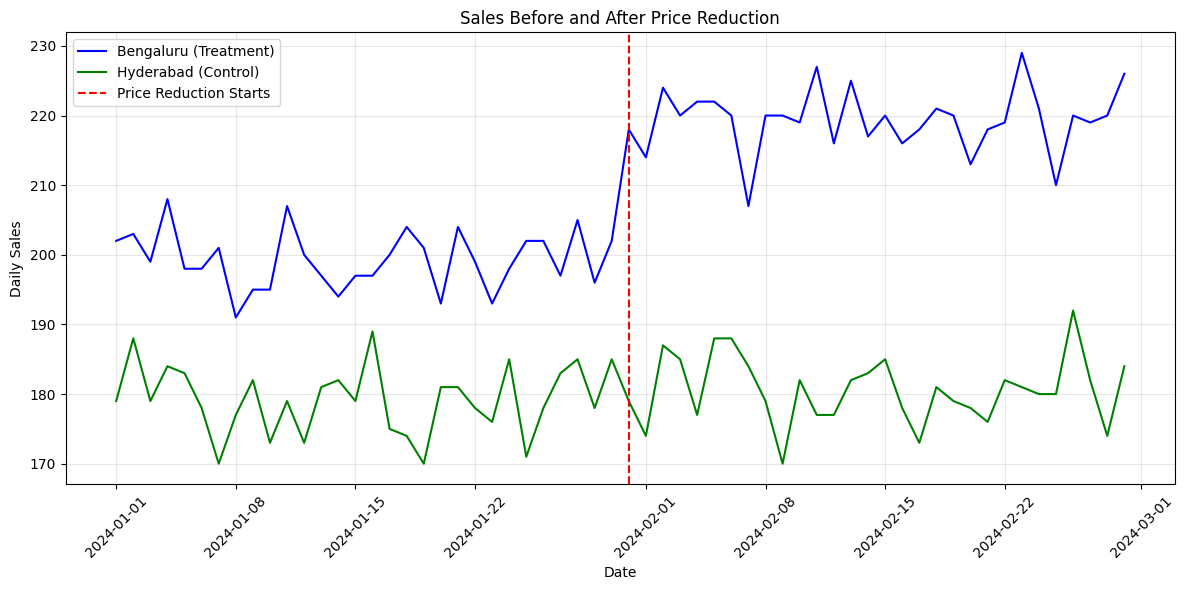

In [4]:

# Separate data for each region
bengaluru = sim_df[sim_df["Region"] == "Bengaluru"]
hyderabad = sim_df[sim_df["Region"] == "Hyderabad"]

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    bengaluru["Date"],
    bengaluru["Sales"],
    label="Bengaluru (Treatment)",
    color="blue"
)

plt.plot(
    hyderabad["Date"],
    hyderabad["Sales"],
    label="Hyderabad (Control)",
    color="green"
)

# Mark the price reduction date
plt.axvline(
    x=pd.Timestamp("2024-01-31"),
    color="red",
    linestyle="--",
    label="Price Reduction Starts"
)

plt.title("Sales Before and After Price Reduction")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [5]:

# Define the intervention date
intervention_date = pd.Timestamp("2024-01-31")

# Label each observation as Before or After
sim_df["Period"] = np.where(
    sim_df["Date"] < intervention_date,
    "Before",
    "After"
)

# Calculate average daily sales by region and period
avg_sales = sim_df.groupby(
    ["Region", "Period"]
)["Sales"].mean().unstack()

print("Average Daily Sales:")
print(avg_sales)

# Calculate changes in sales
bengaluru_change = (
    avg_sales.loc["Bengaluru", "After"]
    - avg_sales.loc["Bengaluru", "Before"]
)

hyderabad_change = (
    avg_sales.loc["Hyderabad", "After"]
    - avg_sales.loc["Hyderabad", "Before"]
)

# Difference-in-Differences estimate
did_effect = bengaluru_change - hyderabad_change

print("\nBengaluru Change:", round(bengaluru_change, 2))
print("Hyderabad Change:", round(hyderabad_change, 2))
print("Estimated DiD Effect:", round(did_effect, 2))


Average Daily Sales:
Period          After      Before
Region                           
Bengaluru  219.366667  199.266667
Hyderabad  180.566667  179.200000

Bengaluru Change: 20.1
Hyderabad Change: 1.37
Estimated DiD Effect: 18.73


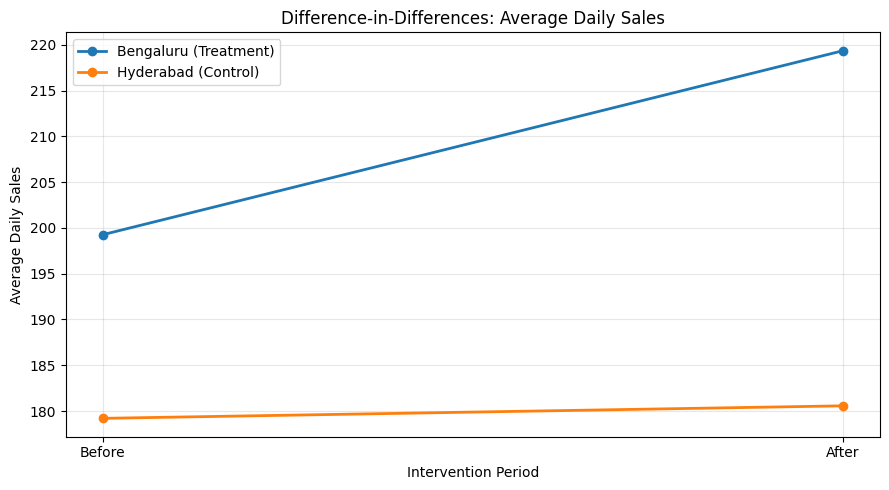

In [6]:

# Prepare data for DiD visualization
periods = ["Before", "After"]

bengaluru_avg = [
    avg_sales.loc["Bengaluru", "Before"],
    avg_sales.loc["Bengaluru", "After"]
]

hyderabad_avg = [
    avg_sales.loc["Hyderabad", "Before"],
    avg_sales.loc["Hyderabad", "After"]
]

# Create chart
plt.figure(figsize=(9, 5))

plt.plot(
    periods,
    bengaluru_avg,
    marker="o",
    linewidth=2,
    label="Bengaluru (Treatment)"
)

plt.plot(
    periods,
    hyderabad_avg,
    marker="o",
    linewidth=2,
    label="Hyderabad (Control)"
)

plt.title("Difference-in-Differences: Average Daily Sales")
plt.xlabel("Intervention Period")
plt.ylabel("Average Daily Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:

# Check regions in our simulated dataset
print("Available regions:")
print(sim_df["Region"].unique())

print("\nNumber of regions:")
print(sim_df["Region"].nunique())


Available regions:
['Bengaluru' 'Hyderabad']

Number of regions:
2


In [8]:

# Generate an expanded simulated dataset
np.random.seed(42)

regions = {
    "Bengaluru": 200,
    "Hyderabad": 180,
    "Chennai": 210,
    "Pune": 190
}

expanded_data = []

for day in range(60):
    for region, base_demand in regions.items():

        price = 100

        # Only Bengaluru receives the price reduction
        if region == "Bengaluru" and day >= 30:
            price = 90

        # Simulated effect of the price reduction
        price_effect = (100 - price) * 2

        # Common daily variation plus random noise
        common_trend = 0.1 * day
        noise = np.random.normal(0, 5)

        sales = (
            base_demand
            + common_trend
            + price_effect
            + noise
        )

        expanded_data.append([
            dates[day],
            region,
            price,
            round(sales)
        ])

# Create expanded DataFrame
expanded_df = pd.DataFrame(
    expanded_data,
    columns=["Date", "Region", "Price", "Sales"]
)

print(expanded_df.head(10))
print("\nDataset shape:", expanded_df.shape)
print("\nAvailable regions:", expanded_df["Region"].unique())


        Date     Region  Price  Sales
0 2024-01-01  Bengaluru    100    202
1 2024-01-01  Hyderabad    100    179
2 2024-01-01    Chennai    100    213
3 2024-01-01       Pune    100    198
4 2024-01-02  Bengaluru    100    199
5 2024-01-02  Hyderabad    100    179
6 2024-01-02    Chennai    100    218
7 2024-01-02       Pune    100    194
8 2024-01-03  Bengaluru    100    198
9 2024-01-03  Hyderabad    100    183

Dataset shape: (240, 4)

Available regions: ['Bengaluru' 'Hyderabad' 'Chennai' 'Pune']


In [9]:

# Convert regional sales into separate columns
sales_pivot = expanded_df.pivot(
    index="Date",
    columns="Region",
    values="Sales"
)

# Display the first 10 rows
print(sales_pivot.head(10))

# Check dataset shape
print("\nDataset shape:", sales_pivot.shape)


Region      Bengaluru  Chennai  Hyderabad  Pune
Date                                           
2024-01-01        202      213        179   198
2024-01-02        199      218        179   194
2024-01-03        198      208        183   188
2024-01-04        202      202        171   187
2024-01-05        195      206        182   183
2024-01-06        208      211        179   183
2024-01-07        198      205        181   192
2024-01-08        198      208        179   200
2024-01-09        201      215        176   185
2024-01-10        202      204        171   192

Dataset shape: (60, 4)


In [10]:

from scipy.optimize import minimize

# Select only dates before the intervention
pre_data = sales_pivot.loc[
    sales_pivot.index < "2024-01-31"
]

# Bengaluru is the treatment region
y = pre_data["Bengaluru"].values

# Other regions are the controls
control_regions = ["Hyderabad", "Chennai", "Pune"]
X = pre_data[control_regions].values

# Minimize the difference between actual and synthetic sales
def objective(weights):
    synthetic_sales = X @ weights
    return np.mean((y - synthetic_sales) ** 2)

# Start with equal weights
initial_weights = np.array([1/3, 1/3, 1/3])

# Weights must add up to 1
constraints = [
    {"type": "eq", "fun": lambda w: np.sum(w) - 1}
]

# Each weight must be between 0 and 1
bounds = [(0, 1)] * 3

# Find the best weights
result = minimize(
    objective,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

if not result.success:
    raise RuntimeError(result.message)

# Display weights
for region, weight in zip(control_regions, result.x):
    print(f"{region}: {weight:.4f}")

print("Total Weight:", round(sum(result.x), 4))


Hyderabad: 0.2076
Chennai: 0.5663
Pune: 0.2260
Total Weight: 1.0


In [11]:

# Calculate Synthetic Bengaluru using control region weights
sales_pivot["Synthetic_Bengaluru"] = (
    sales_pivot[control_regions].values @ result.x
)

# Compare actual and synthetic sales
comparison = sales_pivot[
    ["Bengaluru", "Synthetic_Bengaluru"]
]

print(comparison.head(10))

# Calculate pre-intervention RMSE
pre_comparison = comparison.loc[
    comparison.index < "2024-01-31"
]

rmse = np.sqrt(
    np.mean(
        (
            pre_comparison["Bengaluru"]
            - pre_comparison["Synthetic_Bengaluru"]
        ) ** 2
    )
)

print("\nPre-intervention RMSE:", round(rmse, 2))


Region      Bengaluru  Synthetic_Bengaluru
Date                                      
2024-01-01        202           202.549974
2024-01-02        199           204.477447
2024-01-03        198           198.288424
2024-01-04        202           192.172862
2024-01-05        195           195.817926
2024-01-06        208           198.026681
2024-01-07        198           197.078350
2024-01-08        198           200.170417
2024-01-09        201           200.121192
2024-01-10        202           194.435731

Pre-intervention RMSE: 4.81


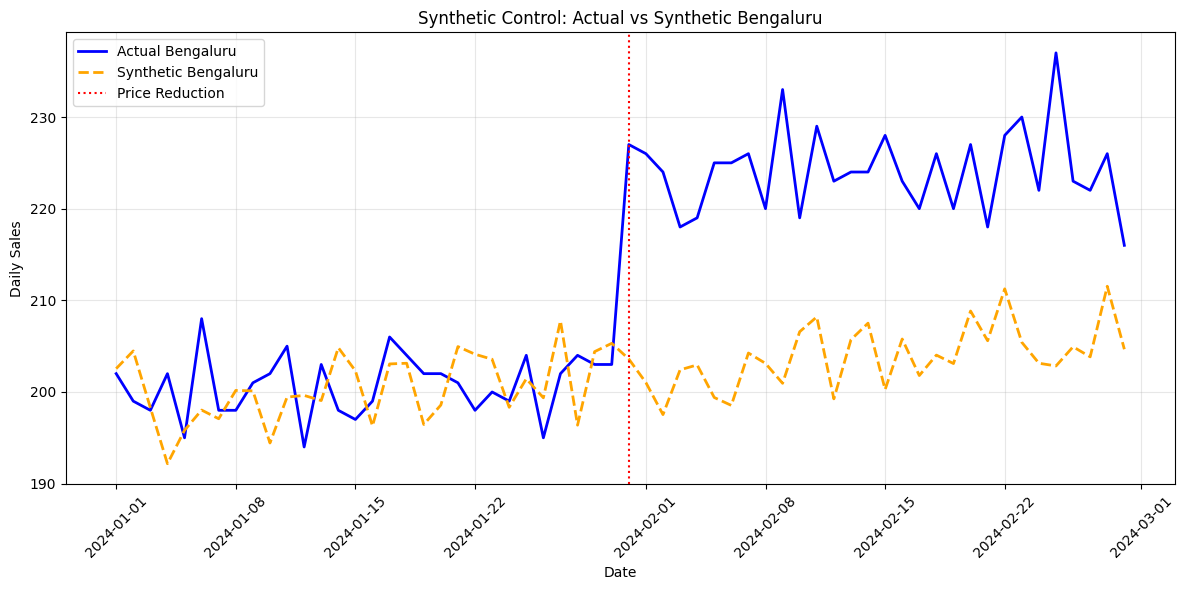

In [12]:

# Plot actual and synthetic Bengaluru sales
plt.figure(figsize=(12, 6))

plt.plot(
    comparison.index,
    comparison["Bengaluru"],
    label="Actual Bengaluru",
    color="blue",
    linewidth=2
)

plt.plot(
    comparison.index,
    comparison["Synthetic_Bengaluru"],
    label="Synthetic Bengaluru",
    color="orange",
    linestyle="--",
    linewidth=2
)

# Mark the intervention date
plt.axvline(
    x=pd.Timestamp("2024-01-31"),
    color="red",
    linestyle=":",
    label="Price Reduction"
)

plt.title("Synthetic Control: Actual vs Synthetic Bengaluru")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:
post_comparison = comparison.loc[
    comparison.index >= "2024-01-31"
].copy()

post_comparison["TreatmentEffect"] = (
    post_comparison["Bengaluru"]
    - post_comparison["Synthetic_Bengaluru"]
)

average_effect = post_comparison["TreatmentEffect"].mean()

print("Average Treatment Effect:", round(average_effect, 2))
print("Total Estimated Additional Sales:",
      round(post_comparison["TreatmentEffect"].sum(), 2))

Average Treatment Effect: 20.33
Total Estimated Additional Sales: 610.01


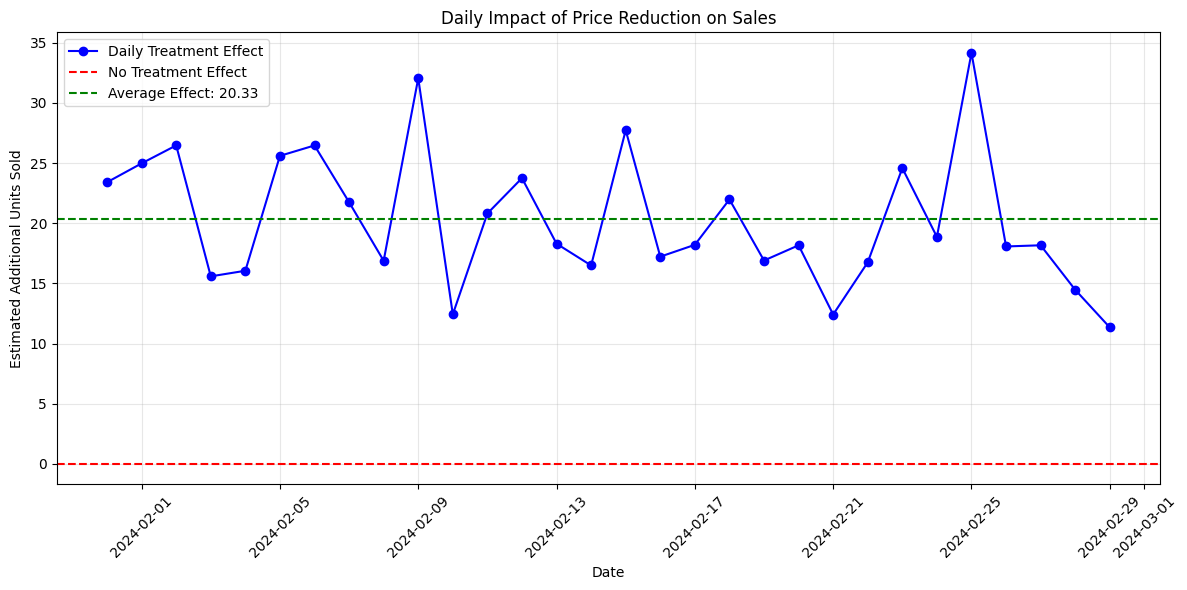

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    post_comparison.index,
    post_comparison["TreatmentEffect"],
    color="blue",
    marker="o",
    label="Daily Treatment Effect"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="No Treatment Effect"
)

plt.axhline(
    y=average_effect,
    color="green",
    linestyle="--",
    label=f"Average Effect: {average_effect:.2f}"
)

plt.title("Daily Impact of Price Reduction on Sales")
plt.xlabel("Date")
plt.ylabel("Estimated Additional Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# Placebo test for Hyderabad

placebo_pre = sales_pivot.loc[
    sales_pivot.index < "2024-01-31"
]

placebo_post = sales_pivot.loc[
    sales_pivot.index >= "2024-01-31"
]

# Compare Hyderabad with another untreated region
placebo_gap = (
    sales_pivot["Hyderabad"]
    - sales_pivot["Pune"]
)

placebo_effect = (
    placebo_gap.loc[placebo_gap.index >= "2024-01-31"].mean()
    - placebo_gap.loc[placebo_gap.index < "2024-01-31"].mean()
)

print("Hyderabad Placebo Effect:", round(placebo_effect, 2))
print("Bengaluru Treatment Effect:", round(average_effect, 2))

Hyderabad Placebo Effect: 1.23
Bengaluru Treatment Effect: 20.33


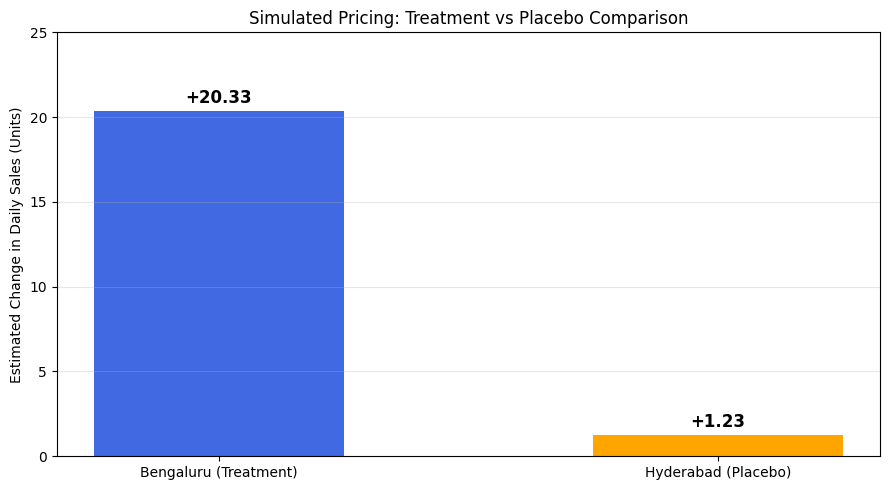

In [16]:
import matplotlib.pyplot as plt

regions = ["Bengaluru (Treatment)", "Hyderabad (Placebo)"]
effects = [average_effect, placebo_effect]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    regions,
    effects,
    color=["royalblue", "orange"],
    width=0.5
)

for bar, effect in zip(bars, effects):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"+{effect:.2f}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title("Simulated Pricing: Treatment vs Placebo Comparison")
plt.ylabel("Estimated Change in Daily Sales (Units)")
plt.ylim(0, 25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Synthetic Control Placebo Test for Hyderabad

placebo_controls = ["Chennai", "Pune"]

pre_data = sales_pivot.loc[
    sales_pivot.index < "2024-01-31"
]

y_placebo = pre_data["Hyderabad"].values
X_placebo = pre_data[placebo_controls].values

def placebo_objective(weights):
    predicted = X_placebo @ weights
    return np.mean((y_placebo - predicted) ** 2)

placebo_result = minimize(
    placebo_objective,
    x0=[0.5, 0.5],
    method="SLSQP",
    bounds=[(0, 1), (0, 1)],
    constraints=[
        {"type": "eq", "fun": lambda w: sum(w) - 1}
    ]
)

if not placebo_result.success:
    raise RuntimeError(placebo_result.message)

print("Hyderabad Synthetic Control Weights:")
for region, weight in zip(placebo_controls, placebo_result.x):
    print(f"{region}: {weight:.4f}")

print("Total Weight:", round(sum(placebo_result.x), 4))

Hyderabad Synthetic Control Weights:
Chennai: 0.0000
Pune: 1.0000
Total Weight: 1.0


In [18]:
import numpy as np

# Predict Hyderabad using its synthetic control
synthetic_hyderabad = (
    sales_pivot[placebo_controls].values @ placebo_result.x
)

# Compare actual and synthetic sales before intervention
actual_pre = pre_data["Hyderabad"].values
synthetic_pre = (
    pre_data[placebo_controls].values @ placebo_result.x
)

placebo_rmse = np.sqrt(
    np.mean((actual_pre - synthetic_pre) ** 2)
)

print("Hyderabad Placebo RMSE:", round(placebo_rmse, 2))
print("Bengaluru Pre-intervention RMSE:", round(rmse, 2))

Hyderabad Placebo RMSE: 12.51
Bengaluru Pre-intervention RMSE: 4.81


In [19]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Use only pre-intervention data for training
X_train = pre_data[["Chennai", "Pune"]]
y_train = pre_data["Hyderabad"]

# Fit model with a baseline adjustment
placebo_model = LinearRegression(
    positive=True,
    fit_intercept=True
)

placebo_model.fit(X_train, y_train)

# Predict Hyderabad before intervention
predicted_pre = placebo_model.predict(X_train)

# Calculate improved RMSE
improved_rmse = np.sqrt(
    np.mean((y_train - predicted_pre) ** 2)
)

print("Original Hyderabad RMSE:", round(placebo_rmse, 2))
print("Improved Hyderabad RMSE:", round(improved_rmse, 2))
print("Intercept:", round(placebo_model.intercept_, 2))
print("Weights:", placebo_model.coef_)

Original Hyderabad RMSE: 12.51
Improved Hyderabad RMSE: 4.9
Intercept: 138.5
Weights: [0.02308942 0.19565381]


In [20]:
# Predict Hyderabad for all 60 days
sales_pivot["Improved_Synthetic_Hyderabad"] = (
    placebo_model.predict(sales_pivot[["Chennai", "Pune"]])
)

# Calculate actual minus predicted sales
sales_pivot["Hyderabad_Gap"] = (
    sales_pivot["Hyderabad"]
    - sales_pivot["Improved_Synthetic_Hyderabad"]
)

# Separate before and after periods
pre_gap = sales_pivot.loc[
    sales_pivot.index < "2024-01-31",
    "Hyderabad_Gap"
]

post_gap = sales_pivot.loc[
    sales_pivot.index >= "2024-01-31",
    "Hyderabad_Gap"
]

# Estimate change in the placebo gap
improved_placebo_effect = post_gap.mean() - pre_gap.mean()

print("Improved Hyderabad Placebo Effect:",
      round(improved_placebo_effect, 2))

print("Bengaluru Treatment Effect:",
      round(average_effect, 2))

Improved Hyderabad Placebo Effect: 3.98
Bengaluru Treatment Effect: 20.33


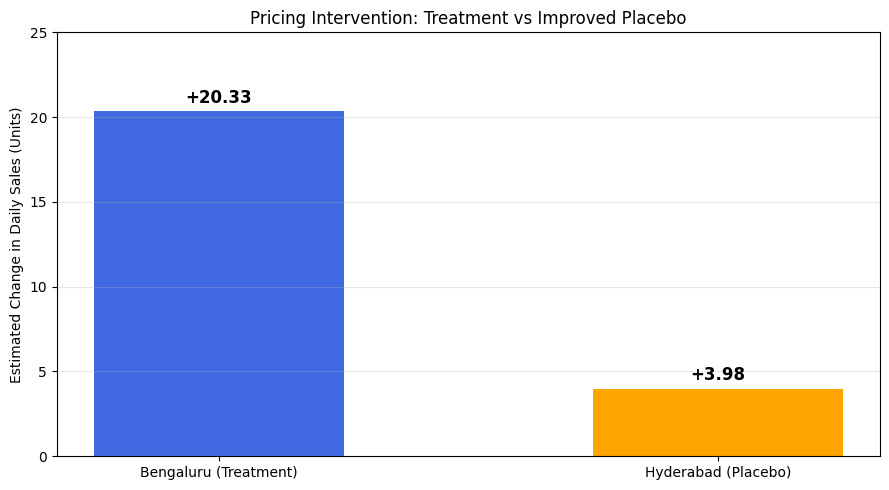

In [21]:
import matplotlib.pyplot as plt

regions = ["Bengaluru (Treatment)", "Hyderabad (Placebo)"]
effects = [average_effect, improved_placebo_effect]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    regions,
    effects,
    color=["royalblue", "orange"],
    width=0.5
)

for bar, effect in zip(bars, effects):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"+{effect:.2f}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title("Pricing Intervention: Treatment vs Improved Placebo")
plt.ylabel("Estimated Change in Daily Sales (Units)")
plt.ylim(0, 25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:
# Calculate price elasticity for Bengaluru

bengaluru_data = expanded_df[
    expanded_df["Region"] == "Bengaluru"
]

before = bengaluru_data[
    bengaluru_data["Date"] < "2024-01-31"
]

after = bengaluru_data[
    bengaluru_data["Date"] >= "2024-01-31"
]

price_before = before["Price"].mean()
price_after = after["Price"].mean()

sales_before = before["Sales"].mean()
sales_after = after["Sales"].mean()

price_change_pct = (
    (price_after - price_before) / price_before
) * 100

sales_change_pct = (
    (sales_after - sales_before) / sales_before
) * 100

elasticity = sales_change_pct / price_change_pct

print("Price Change (%):", round(price_change_pct, 2))
print("Sales Change (%):", round(sales_change_pct, 2))
print("Price Elasticity:", round(elasticity, 2))

Price Change (%): -10.0
Sales Change (%): 11.72
Price Elasticity: -1.17


In [23]:
# Step 11: Synthetic-Control-Adjusted Price Elasticity

# Average expected sales without price reduction
expected_sales = post_comparison[
    "Synthetic_Bengaluru"
].mean()

# Estimated additional daily sales
additional_sales = average_effect

# Percentage increase relative to expected sales
causal_sales_change_pct = (
    additional_sales / expected_sales
) * 100

# Percentage change in price
price_change_pct = -10

# Synthetic-control-adjusted elasticity
causal_elasticity = (
    causal_sales_change_pct / price_change_pct
)

print("Expected Sales Without Price Change:",
      round(expected_sales, 2))

print("Estimated Additional Daily Sales:",
      round(additional_sales, 2))

print("Estimated Sales Increase (%):",
      round(causal_sales_change_pct, 2))

print("Synthetic-Control-Adjusted Elasticity:",
      round(causal_elasticity, 2))

Expected Sales Without Price Change: 203.93
Estimated Additional Daily Sales: 20.33
Estimated Sales Increase (%): 9.97
Synthetic-Control-Adjusted Elasticity: -1.0


In [24]:
# Step 12: DiD using the same four-region dataset

did_data = expanded_df[
    expanded_df["Region"].isin(["Bengaluru", "Hyderabad"])
].copy()

did_data["Period"] = np.where(
    did_data["Date"] < pd.Timestamp("2024-01-31"),
    "Before",
    "After"
)

did_table = did_data.groupby(
    ["Region", "Period"]
)["Sales"].mean().unstack()

treated_change = (
    did_table.loc["Bengaluru", "After"]
    - did_table.loc["Bengaluru", "Before"]
)

control_change = (
    did_table.loc["Hyderabad", "After"]
    - did_table.loc["Hyderabad", "Before"]
)

expanded_did_effect = treated_change - control_change

print("DiD Effect:", round(expanded_did_effect, 2))
print("Synthetic Control Effect:", round(average_effect, 2))

DiD Effect: 18.8
Synthetic Control Effect: 20.33


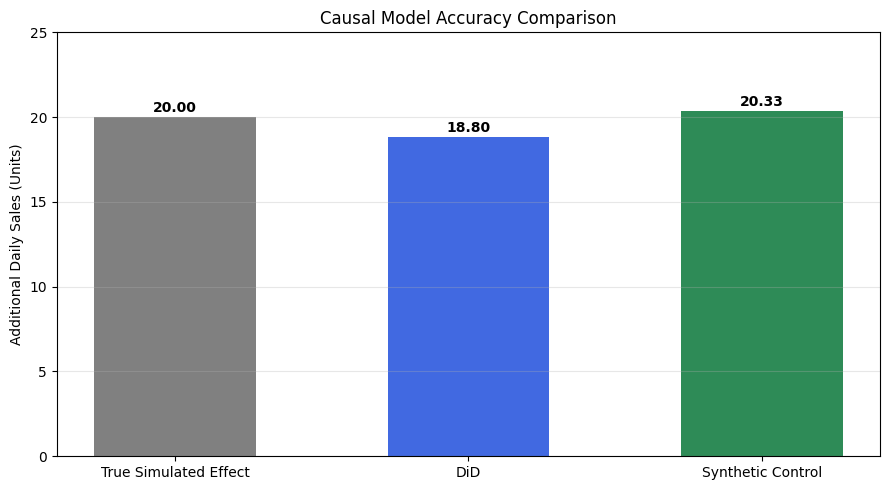

In [25]:
import matplotlib.pyplot as plt

methods = ["True Simulated Effect", "DiD", "Synthetic Control"]
effects = [20, expanded_did_effect, average_effect]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    methods,
    effects,
    color=["gray", "royalblue", "seagreen"],
    width=0.55
)

for bar, value in zip(bars, effects):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{value:.2f}",
        ha="center",
        fontweight="bold"
    )

plt.title("Causal Model Accuracy Comparison")
plt.ylabel("Additional Daily Sales (Units)")
plt.ylim(0, 25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

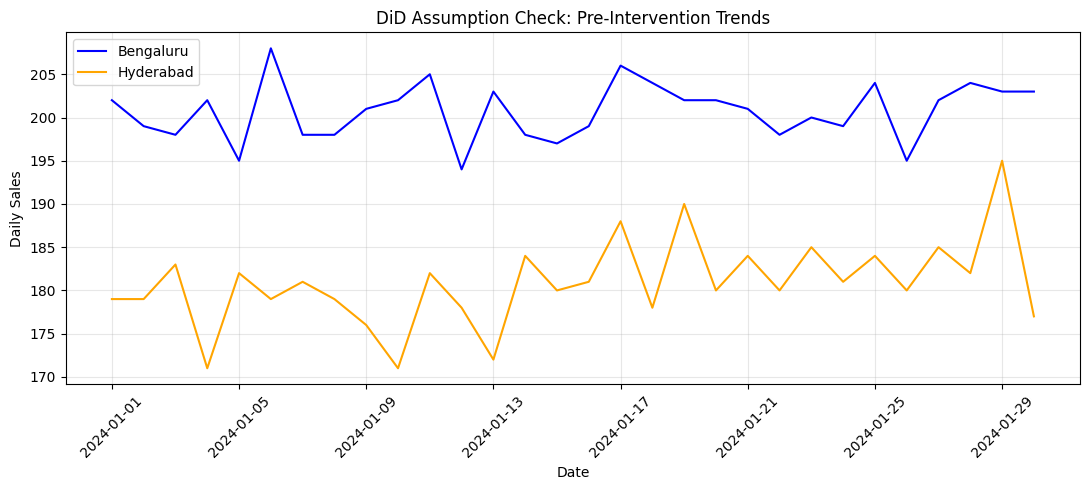

In [26]:
# Check pre-intervention trends

pre_period = sales_pivot.loc[
    sales_pivot.index < "2024-01-31"
]

plt.figure(figsize=(11, 5))

plt.plot(
    pre_period.index,
    pre_period["Bengaluru"],
    label="Bengaluru",
    color="blue"
)

plt.plot(
    pre_period.index,
    pre_period["Hyderabad"],
    label="Hyderabad",
    color="orange"
)

plt.title("DiD Assumption Check: Pre-Intervention Trends")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
import numpy as np

# Pre-intervention sales
pre_period = sales_pivot.loc[
    sales_pivot.index < "2024-01-31"
]

days = np.arange(len(pre_period))

# Estimate daily sales trend for each region
bengaluru_slope = np.polyfit(
    days, pre_period["Bengaluru"], 1
)[0]

hyderabad_slope = np.polyfit(
    days, pre_period["Hyderabad"], 1
)[0]

print("Bengaluru Daily Trend:", round(bengaluru_slope, 4))
print("Hyderabad Daily Trend:", round(hyderabad_slope, 4))
print("Difference in Trends:",
      round(bengaluru_slope - hyderabad_slope, 4))

Bengaluru Daily Trend: 0.0596
Hyderabad Daily Trend: 0.2487
Difference in Trends: -0.1891
